# ESCM 2.0 — From two-neuron replacement to a five-pixel edge

## Scientific objective

Notebook 16 demonstrated candidate switching in a **two-neuron** network at input strength $\beta\in\{14,18,22\}$ and cross-inhibitory jump $g=0.5$. This notebook tests whether the same mechanism supports **two coherent five-pixel edges**. We do not introduce adaptation, depression, or a custom persistence gate.

Our first experiment is deliberately controlled: ten ordinary LIF neurons, five in the old edge and five in the new edge. Every neuron has an assignment-based autapse. We extend the two-neuron cross-inhibition rule to five-to-five connectivity, normalizing each receiver's incoming weights so that the **total synaptic jump from an entire simultaneously firing opposing edge is $g$**, not $5g$. This makes the new experiment meaningfully comparable to notebook 16.

We separately test cooperation between adjacent pixels, not confound it with the initial scaling experiment. Two five-pixel edges are the first spatial test, **not** yet a full event-camera simulation. All inputs and connections are explicit; no custom Brian2 events or modified scheduling.

**Success:** all five old pixels persist in the old-only control; all five new pixels persist in the new-only control; during replacement, all five new pixels sustain activity and every old pixel becomes silent. Persistence means at least two spikes **per pixel in each of two disjoint late windows**, not merely one spike after stimulation.

## 1. Equations and hypotheses

Every neuron obeys

$$
\tau_m\dot v_i=-v_i+X_i+E_i-I_i,\qquad
\tau_x\dot X_i=-X_i,\quad
\tau_E\dot E_i=-E_i,\quad
\tau_I\dot I_i=-I_i.
$$

On each neuronal spike: $v_i\leftarrow0$, $E_i\leftarrow W_E$ via an ordinary autapse. For every cross-edge connection $j\to i$, $I_i\leftarrow I_i+w_{ji}$.

To connect two five-pixel populations without accidentally multiplying the strength of inhibition fivefold, let the cross-edge kernel be $K_{ji}=\exp[-d_{ji}^2/(2\sigma_I^2)]$ and choose

$$
w_{ji}=g\frac{K_{ji}}{\sum_{k\in\mathrm{opposing\ edge}}K_{ki}}.
$$

Thus $\sum_jw_{ji}=g$ for each receiver. This is **a comparison-normalization convention**, not a claim that biological inhibition is normalized this way. We show what happens without spatial cooperation and then add local *between-neuron* excitation within each edge.

Camera stimulus: three spikes at 2, 4, 6 ms for the old edge, and 35, 37, 39 ms for the new edge. The same input train is applied to every pixel in that edge. Evaluate firing in [70,85) and [85,100) ms; total duration 110 ms.

The prior two-neuron success does **not** imply that normalized five-pixel inhibition will succeed: synchronized competition between five neurons may introduce new dynamics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"

n_edge = 5
n = 2*n_edge
old = np.arange(n_edge)
new = np.arange(n_edge, n)
xy = np.column_stack((np.r_[np.ones(n_edge), np.full(n_edge, 4)],
                      np.tile(np.arange(n_edge), 2)))

tm, tx, te, ti = 10.0, 3.0, 5.0, 12.0  # ms
vth, self_weight = 1.0, 8.0
sigma_i = 2.5

print("Old-edge neuron positions:", xy[old].tolist())
print("New-edge neuron positions:", xy[new].tolist())

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Old-edge neuron positions: [[1.0, 0.0], [1.0, 1.0], [1.0, 2.0], [1.0, 3.0], [1.0, 4.0]]
New-edge neuron positions: [[4.0, 0.0], [4.0, 1.0], [4.0, 2.0], [4.0, 3.0], [4.0, 4.0]]


## 2. Minimal spatial model

The only switch in the model is `cooperation`: when positive, nearby neurons **within the same edge** deliver a normalized additive lateral excitatory current. The baseline has zero lateral excitation so that its differences from notebook 16 are attributable to scaling from one to five neurons.

The code constructs only connected Brian2 `Synapses` objects. Identifiers avoid the `E`/`I` symbolic-name collision documented in notebook 12. All dynamic states start at zero.

In [2]:
def simulate(protocol, drive=14.0, inhibition=0.5, cooperation=0.0,
             dt_ms=0.05, record=False):
    b2.start_scope()
    b2.defaultclock.dt = dt_ms*b2.ms

    stimulus_ids, stimulus_times = [], []
    if protocol in ("old_only", "replacement"):
        stimulus_ids.extend(np.tile(old, 3))
        stimulus_times.extend(np.repeat([2.0, 4.0, 6.0], len(old)))
    if protocol in ("new_only", "replacement"):
        stimulus_ids.extend(np.tile(new, 3))
        stimulus_times.extend(np.repeat([35.0, 37.0, 39.0], len(new)))
    order = np.argsort(stimulus_times, kind="stable")
    camera = b2.SpikeGeneratorGroup(n, np.asarray(stimulus_ids, dtype=int)[order],
                                   np.asarray(stimulus_times)[order]*b2.ms)

    params = dict(tau_m=tm*b2.ms, tau_x=tx*b2.ms,
                  tau_e=te*b2.ms, tau_i=ti*b2.ms,
                  threshold_value=vth, self_gain=self_weight, input_gain=drive)
    neurons = b2.NeuronGroup(n, """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_x : 1
        dIexc/dt = -Iexc/tau_e : 1
        dIinh/dt = -Iinh/tau_i : 1
    """, threshold="v > threshold_value", reset="v = 0",
        method="exact", namespace=params)
    neurons.v = neurons.Iext = neurons.Iexc = neurons.Iinh = 0

    feed = b2.Synapses(camera, neurons, on_pre="Iext_post += input_gain",
                       namespace=params)
    feed.connect(j="i")
    autapse = b2.Synapses(neurons, neurons, on_pre="Iexc_post = self_gain",
                          namespace=params)
    autapse.connect(i=np.arange(n), j=np.arange(n))
    objects = [camera, neurons, feed, autapse]

    if inhibition > 0:
        pre, post, weights = [], [], []
        for target in range(n):
            sources = new if target in old else old
            distances = np.linalg.norm(xy[sources] - xy[target], axis=1)
            kernel = np.exp(-distances**2/(2*sigma_i**2))
            normalized = inhibition*kernel/kernel.sum()
            for source, weight in zip(sources, normalized):
                pre.append(int(source)); post.append(target); weights.append(weight)
        cross = b2.Synapses(neurons, neurons, model="w : 1",
                            on_pre="Iinh_post += w")
        cross.connect(i=pre, j=post)
        cross.w = weights
        objects.append(cross)

    if cooperation > 0:
        pre, post, weights = [], [], []
        for target in range(n):
            group = old if target in old else new
            sources = group[group != target]
            distance = np.abs(xy[sources, 1] - xy[target, 1])
            local = sources[distance == 1]
            for source in local:
                pre.append(int(source)); post.append(target)
                weights.append(cooperation/len(local))
        lateral = b2.Synapses(neurons, neurons, model="w : 1",
                             on_pre="Iexc_post += w")
        lateral.connect(i=pre, j=post)
        lateral.w = weights
        objects.append(lateral)

    spikes = b2.SpikeMonitor(neurons)
    objects.append(spikes)
    if record:
        states = b2.StateMonitor(neurons, ("v", "Iexc", "Iinh"),
                                 record=[int(old[2]), int(new[2])], when="end")
        objects.append(states)
    b2.Network(*objects).run(110*b2.ms)
    result = {"t": np.asarray(spikes.t/b2.ms), "i": np.asarray(spikes.i, dtype=int)}
    if record:
        result["state_t"] = np.asarray(states.t/b2.ms)
        result["states"] = {k: np.asarray(getattr(states, k)).copy()
                             for k in ("v", "Iexc", "Iinh")}
        assert all(np.isfinite(x).all() for x in result["states"].values())
    return result


def edge_counts(run, pixels, left, right):
    return np.asarray([np.count_nonzero((run["i"] == i) &
                      (run["t"] >= left) & (run["t"] < right))
                      for i in pixels], dtype=int)


def evaluate(drive, inhibition, cooperation=0., dt_ms=0.05):
    controls = {p: simulate(p, drive, inhibition, cooperation, dt_ms)
                for p in ("old_only", "new_only", "replacement")}
    count = lambda label, group, a, b: edge_counts(controls[label], group, a, b)
    old_a, old_b = count("old_only", old, 70, 85), count("old_only", old, 85, 100)
    new_a, new_b = count("new_only", new, 70, 85), count("new_only", new, 85, 100)
    switched_old_a = count("replacement", old, 70, 85)
    switched_old_b = count("replacement", old, 85, 100)
    switched_new_a = count("replacement", new, 70, 85)
    switched_new_b = count("replacement", new, 85, 100)
    return dict(drive=drive, inhibition=inhibition, cooperation=cooperation,
                dt_ms=dt_ms,
                old_control_pixels=int(np.sum((old_a >= 2) & (old_b >= 2))),
                new_control_pixels=int(np.sum((new_a >= 2) & (new_b >= 2))),
                old_silent_pixels=int(np.sum((switched_old_a == 0) & (switched_old_b == 0))),
                new_persistent_pixels=int(np.sum((switched_new_a >= 2) &
                                                 (switched_new_b >= 2))),
                success=bool(np.all((old_a >= 2) & (old_b >= 2)) and
                             np.all((new_a >= 2) & (new_b >= 2)) and
                             np.all((switched_old_a == 0) & (switched_old_b == 0)) and
                             np.all((switched_new_a >= 2) & (switched_new_b >= 2))))

## 3. The decisive scaling experiment

First, test exactly the successful two-neuron regime from notebook 16: $g=0.5$, $eta\in\{14,18,22\}$. We also include $g=0$ as a control (without inhibition, the old edge should not be selectively removed). Each case is tested under all three input protocols, so an extinguished old edge in the *old-only* control cannot be misclassified as successful replacement.

We then perform a **small targeted** grid around the known switching region rather than repeating the broad biological mechanism search. We keep the model unchanged between conditions.

In [3]:
baseline = []
for drive in tqdm((14.0, 18.0, 22.0), desc="Two-neuron regime on five-pixel edges"):
    for g in (0.0, 0.5):
        baseline.append(evaluate(drive, g))
baseline = pd.DataFrame(baseline)
display(baseline)

# If the expected zero-inhibition control fails, some interaction other than
# cross inhibition is influencing the old-edge activity.
assert (baseline.loc[baseline.inhibition == 0, "old_silent_pixels"] == 0).all()
print("Successful five-pixel configurations:", int(baseline.success.sum()))

Two-neuron regime on five-pixel edges: 100%|██████████| 3/3 [00:05<00:00,  1.91s/it]


,drive,inhibition,cooperation,dt_ms,old_control_pixels,new_control_pixels,old_silent_pixels,new_persistent_pixels,success
0,14.0,0.0,0.0,0.05,5,5,0,5,False
1,14.0,0.5,0.0,0.05,5,5,5,5,True
2,18.0,0.0,0.0,0.05,5,5,0,5,False
3,18.0,0.5,0.0,0.05,5,5,5,5,True
4,22.0,0.0,0.0,0.05,5,5,0,5,False
5,22.0,0.5,0.0,0.05,5,5,5,5,True


Successful five-pixel configurations: 3


## 4. Check whether local cooperation helps preserve the entire edge

Only after seeing the spatial scaling result do we add cooperative excitation. We compare three fixed, modest within-edge strengths and three cross-inhibition strengths at the same external input. Any improved result must satisfy **all four** per-pixel criteria; a larger number of spikes is not sufficient.

If no configuration satisfies the criteria, the observation is evidence that a two-neuron switching region did not transfer to this five-pixel circuit—not evidence that no spatial architecture can work.

In [4]:
records = []
for cooperation in tqdm((0.0, 0.5, 1.0), desc="Within-edge cooperation"):
    for drive in (14.0, 18.0, 22.0):
        for g in (0.35, 0.5, 0.7):
            records.append(evaluate(drive, g, cooperation))
comparison = pd.DataFrame(records)
display(comparison.sort_values(["success", "new_persistent_pixels",
                                "old_silent_pixels"], ascending=False))
print("Configurations with full replacement:", int(comparison.success.sum()),
      "/", len(comparison))

Within-edge cooperation: 100%|██████████| 3/3 [00:20<00:00,  6.88s/it]


,drive,inhibition,cooperation,dt_ms,old_control_pixels,new_control_pixels,old_silent_pixels,new_persistent_pixels,success
0,14.0,0.35,0.0,0.05,5,5,5,5,True
1,14.0,0.50,0.0,0.05,5,5,5,5,True
3,18.0,0.35,0.0,0.05,5,5,5,5,True
4,18.0,0.50,0.0,0.05,5,5,5,5,True
5,18.0,0.70,0.0,0.05,5,5,5,5,True
6,22.0,0.35,0.0,0.05,5,5,5,5,True
7,22.0,0.50,0.0,0.05,5,5,5,5,True
8,22.0,0.70,0.0,0.05,5,5,5,5,True
10,14.0,0.50,0.5,0.05,5,5,5,5,True
12,18.0,0.35,0.5,0.05,5,5,5,5,True


Configurations with full replacement: 21 / 27


## 5. Visualize actual spatial recruitment and replacement

Plot spike rasters for the best-performing configuration and compare it with the old-only control. Show every pixel separately. A successful configuration requires *all five* new pixels, not a single surviving winner.

The ranking is only for **diagnostic visualization**, not a substitute for the strict Boolean acceptance criteria.

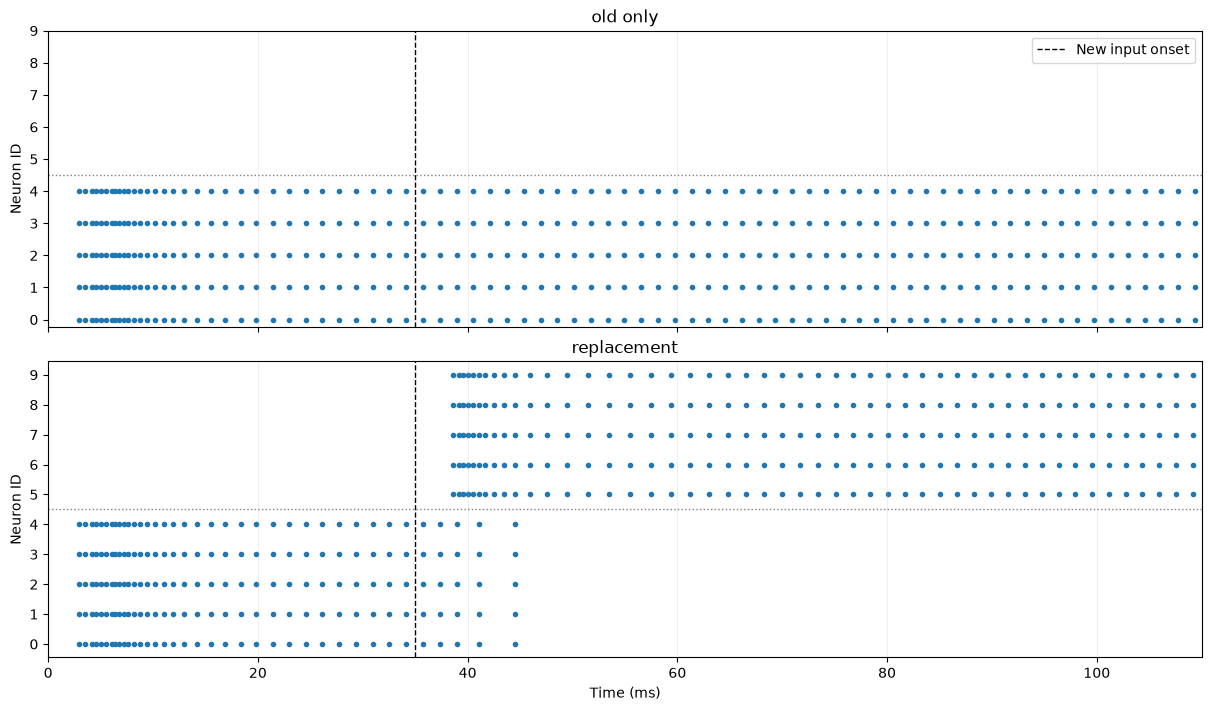

Visualized configuration: {'drive': 14.0, 'inhibition': 0.35, 'cooperation': 0.0}
Acceptance criteria: {'old_control_pixels': 5, 'new_control_pixels': 5, 'old_silent_pixels': 5, 'new_persistent_pixels': 5, 'success': True}


In [5]:
best = comparison.sort_values(["success", "new_persistent_pixels",
                               "old_silent_pixels", "old_control_pixels",
                               "new_control_pixels"], ascending=False).iloc[0]
chosen = dict(drive=float(best.drive), inhibition=float(best.inhibition),
              cooperation=float(best.cooperation))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for ax, protocol in zip(axes, ("old_only", "replacement")):
    result = simulate(protocol, **chosen)
    ax.scatter(result["t"], result["i"], s=9)
    ax.axvline(35, linestyle="--", color="black", lw=1, label="New input onset")
    ax.axhline(4.5, linestyle=":", color="gray", lw=1)
    ax.set(yticks=range(n), ylabel="Neuron ID", title=protocol.replace("_", " "))
    ax.grid(axis="x", alpha=0.2)
axes[-1].set(xlabel="Time (ms)", xlim=(0, 110))
axes[0].legend()
plt.show()
print("Visualized configuration:", chosen)
print("Acceptance criteria:", best[["old_control_pixels", "new_control_pixels",
                                    "old_silent_pixels", "new_persistent_pixels",
                                    "success"]].to_dict())

## 6. Numerical consistency for the best configuration

Repeat the selected configuration at 0.1, 0.05 and 0.025 ms. This is a **finite timestep sensitivity check**, not a proof of convergence. It evaluates the spatial acceptance criteria directly rather than only comparing total spike counts.

If the model succeeds at only one timestep, the spatial switching result is not yet a reliable mechanism.

In [6]:
refinement = []
for dt in tqdm((0.1, 0.05, 0.025), desc="Timestep sensitivity"):
    refinement.append(evaluate(**chosen, dt_ms=dt))
display(pd.DataFrame(refinement))

Timestep sensitivity: 100%|██████████| 3/3 [00:02<00:00,  1.18it/s]


,drive,inhibition,cooperation,dt_ms,old_control_pixels,new_control_pixels,old_silent_pixels,new_persistent_pixels,success
0,14.0,0.35,0.0,0.100,5,5,5,5,True
1,14.0,0.35,0.0,0.050,5,5,5,5,True
2,14.0,0.35,0.0,0.025,5,5,5,5,True


## 7. Interpretation

If the ten-neuron network succeeds, we have demonstrated a **scheduler-free spatial switching mechanism** across two five-pixel populations. The next step is a full pixel grid with irrelevant/background neurons and moving edges, to test spatial leakage and connectivity.

If it fails, inspect whether the new edge never gets recruited or gets recruited and then suppressed. Those are distinct dynamical failures, and the spike raster reveals which occurs. We should not add additional biological mechanisms until this distinction is established.

**Scope:** Two five-pixel populations, Gaussian-normalized cross-edge inhibition, optional within-edge local excitation, specified stimulus timings. These results do not automatically generalize to unconstrained spatial networks, arbitrary phases, or recorded event streams.